In [1]:
import numpy as np
import cobra
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
import pickle
import pandas as pd
import sys
from scipy.stats import spearmanr
sys.path.append('../../')
from helper_function import *
plt.rcParams['font.family'] = 'Arial'

In [2]:
mapping_df = pd.read_csv(
    "iJO1366star_to_AGORA2_mapping.csv")

w_dict = {}
data = mapping_df[mapping_df['orientation'] == 'same'][mapping_df['match_status'].isin(['exact', 'high_similarity'])]
for ag_id, coeff in zip(data['agora_reaction_id'], data['prot_pool_coefficient']):
    w_dict[ag_id] = abs(coeff) * 1000 / 0.3

with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

/tmp/ipykernel_2387/2743879224.py:5: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  data = mapping_df[mapping_df['orientation'] == 'same'][mapping_df['match_status'].isin(['exact', 'high_similarity'])]


In [3]:
from typing import List, Tuple, Optional
from dataclasses import dataclass

@dataclass
class Sample:
    E: np.ndarray      # shape (n,)
    Y: float

with open('../../all_samples_ececoli_wo_normalize_ww.pkl', 'rb') as f:
    ec_samples = pickle.load(f)

# with open('../../all_samples_ecoli_wo_normalize_ww.pkl', 'rb') as f:
#     data = pickle.load(f)
#     ec_samples = data['samples1'] + data['samples2'] + data['samples3'] + data['samples4']

with open('../../all_samples_ecoli_wo_normalize.pkl', 'rb') as f:
    data = pickle.load(f)
    samples = data['samples1'] + data['samples2'] + data['samples3'] + data['samples4']

In [4]:
total_ec_corr = []
total_corr = []

for i in range(20):
    corr = spearmanr(np.array([x.E for x in samples]).T[i], np.array([x.Y for x in samples]))
    ec_corr = spearmanr(np.array([x.E for x in ec_samples]).T[i], np.array([x.Y for x in ec_samples]))
    total_corr.append(corr)
    total_ec_corr.append(ec_corr)

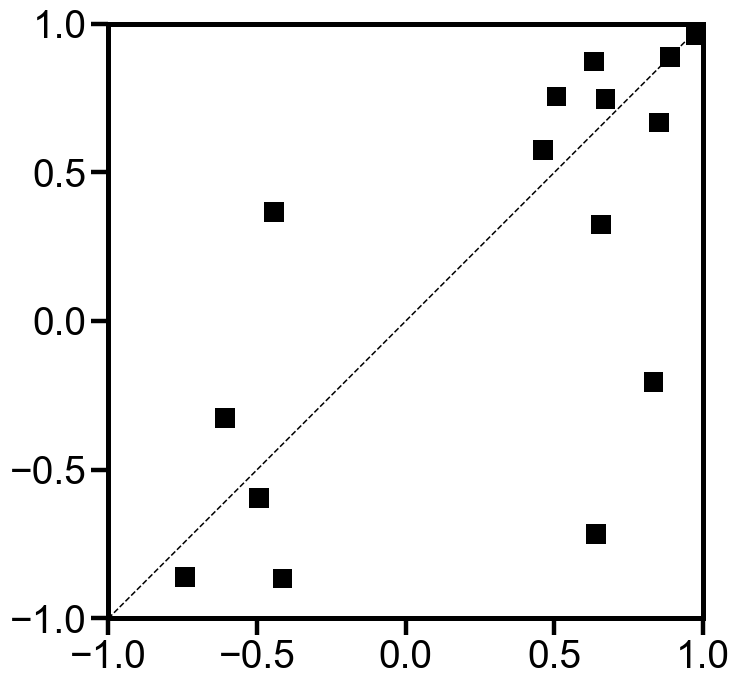

{'r': 0.7050682557977743,
 'p': 0.00228424810179119,
 'ci_low': 0.3218522471805173,
 'ci_high': 0.8897874507444242,
 'n': 16}

In [5]:
set_panel_style(scale=4)

fig, ax = plt.subplots(figsize=(8, 8))

corr_x = []
corr_y = []

for i in range(20):
    if total_corr[i].pvalue < 0.05 and total_ec_corr[i].pvalue < 0.05:
        x = total_corr[i].correlation
        y = total_ec_corr[i].correlation
        corr_x.append(x)
        corr_y.append(y)

        ax.scatter(x, y, s=200, color="black", edgecolors="none", marker="s")

ax.set_box_aspect(1)
ax.set_xlim(-1, 1)
ax.set_ylim(-1, 1)
ax.set_xticks(np.arange(-1, 1.01, 0.5))
ax.set_yticks(np.arange(-1, 1.01, 0.5))

xmin, xmax = ax.get_xlim()
ax.plot([xmin, xmax], [xmin, xmax], "--", color="black", linewidth=1.1)

fig.savefig("Supp_Figure6_ececoli_corr.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)

plt.tight_layout()
plt.show()
pearson_ci(corr_x, corr_y)

In [6]:
with open('../../all_samples_ececoli_wo_normalize_ww.pkl', 'rb') as f:
    C_samples = pickle.load(f)


with open('../../all_samples_ecoli_wo_normalize_ww.pkl', 'rb') as f:
    data = pickle.load(f)
    B_samples = data['samples1'] + data['samples2'] + data['samples3'] + data['samples4']

In [7]:
results = []
for sector_id in range(20):
    if sector_id == 16:
        continue

    delta_sector = [
        y.E[sector_id] - x.E[sector_id]
        for x, y in zip(B_samples, C_samples)
    ]

    delta16 = [
        y.E[16] - x.E[16]
        for x, y in zip(B_samples, C_samples)
    ]

    rho, p = spearmanr(delta_sector, delta16)

    results.append({
        "sector": sector_id,
        "rho_with_delta16": rho,
        "p": p,
    })

sector_corr_df = pd.DataFrame(results)

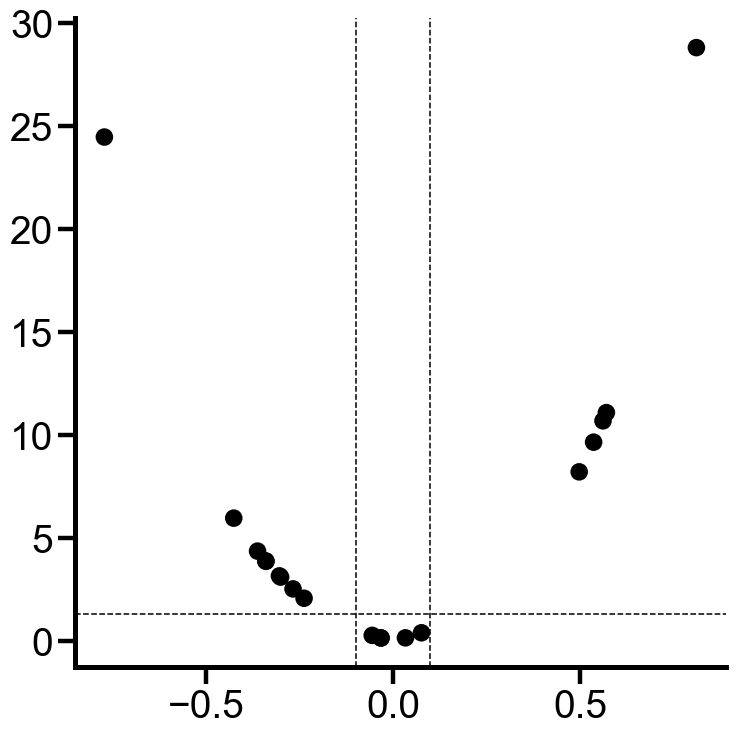

In [8]:
plot_df = sector_corr_df.copy()
plot_df["neg_log10_p"] = -np.log10(plot_df["p"])

point_rgb = (0.0, 0.0, 0.0)
line_rgb = (0.0, 0.0, 0.0)

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    plot_df["rho_with_delta16"],
    plot_df["neg_log10_p"],
    s=160,
    color="black",
    edgecolors="none"
)

ax.axvline(-0.1, linestyle="--", linewidth=1.1, color=line_rgb)
ax.axvline(0.1, linestyle="--", linewidth=1.1, color=line_rgb)
ax.axhline(-np.log10(0.05), linestyle="--", linewidth=1.1, color=line_rgb)


ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

fig.savefig("Supp_Figure6_ececoli_delta.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)

plt.tight_layout()
plt.show()

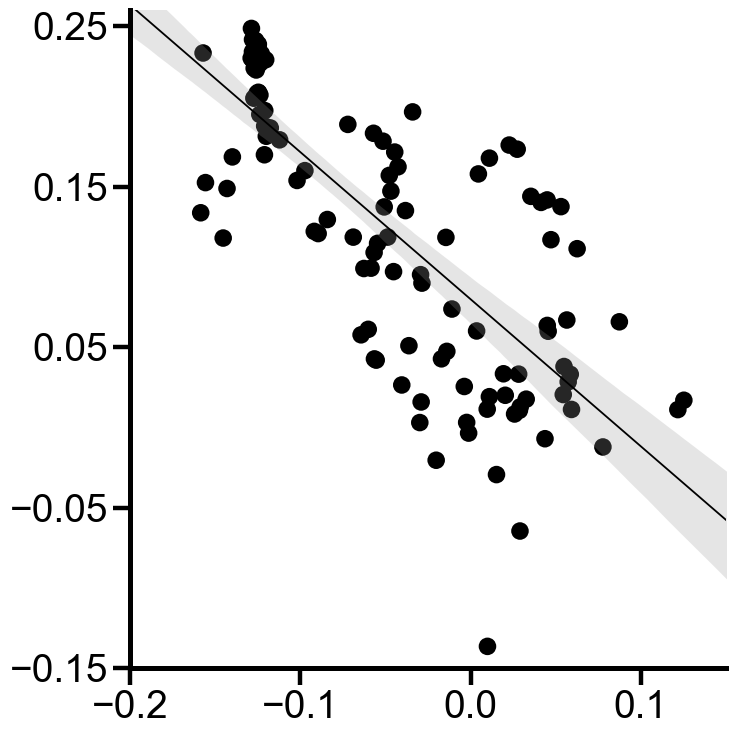

{'rho': -0.7722734046877116,
 'p': 3.3634338697609177e-25,
 'ci_low': -0.8340891067408371,
 'ci_high': -0.6874552105375213,
 'n': 121}

In [9]:
point_rgb = (0.0, 0.0, 0.0)
line_rgb  = (0.0, 0.0, 0.0)
band_rgb  = (0.6, 0.6, 0.6)

delta11 = np.array([
    y.E[11] - x.E[11]
    for x, y in zip(B_samples, C_samples)
])

delta16 = np.array([
    y.E[16] - x.E[16]
    for x, y in zip(B_samples, C_samples)
])

mask = np.isfinite(delta16) & np.isfinite(delta11)
x, y = delta16[mask], delta11[mask]

rho, p = spearmanr(x, y)

m, b = np.polyfit(x, y, 1)
xg = np.linspace(-0.2, 0.2, 200)
yg = m * xg + b

B = 2000
rng = np.random.default_rng(0)
Yhat = np.empty((B, xg.size))
n = x.size

for i in range(B):
    idx = rng.integers(0, n, n)
    m_i, b_i = np.polyfit(x[idx], y[idx], 1)
    Yhat[i] = m_i * xg + b_i

lo, hi = np.percentile(Yhat, [2.5, 97.5], axis=0)

fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    x, y,
    s=160,
    color=point_rgb,
    edgecolors="none"
)

ax.plot(xg, yg, linewidth=1.3, color=line_rgb)
ax.fill_between(xg, lo, hi, alpha=0.25, color=band_rgb, linewidth=0)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.set_xlim(-0.20, 0.15)
ax.set_ylim(-0.15, 0.26)
ax.set_xticks(np.arange(-0.20, 0.15, 0.1))
ax.set_yticks(np.arange(-0.15, 0.26, 0.1))

fig.savefig("Supp_Figure6_ececoli_delta16.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)

plt.tight_layout()
plt.show()

spearman_ci(x, y)

In [10]:
with open(f'../../FBAsolution/M9_sufficient_20_40_proteome.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_met_flux = data['all_met_flux']
    del data

with open(f'../../FBAsolution/M9_sufficient_60_40_proteome.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_met_flux2 = data['all_met_flux']
    del data

with open(f'../../FBAsolution/M9_sufficient_400_40_proteome.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_met_flux3 = data['all_met_flux']
    del data

with open(f'../../FBAsolution/M9_sufficient_423_1_proteome_weakbg.pkl', 'rb') as pickle_file:
    data = pickle.load(pickle_file)
    all_met_flux4 = data['all_met_flux']
    del data

In [11]:
normal_all_met_flux = np.concatenate([
    all_met_flux[:, 51],
    all_met_flux2[:, 51],
    all_met_flux3[:, 51],
    all_met_flux4[:, 51],
]).reshape(-1)

In [12]:
with open('../../FBAsolution/M9_sufficient_eccoli_proteome_weakbg.pkl', 'rb') as f:
    data = pickle.load(f)
    ec_all_met_flux = data['all_met_flux'].reshape(-1)
    ec_all_growth_rate = data['all_growth_rate'].reshape(-1)

with open('../../Coarse_graining_result/clustered_nodes_c20_s44_pq1_relabeled.pkl', 'rb') as f:
    cluster_nodes = pickle.load(f)

In [13]:
import numpy as np
import pandas as pd


def extract_sector_reactions(case_flux, sector_id):
    """
    提取一个 case 中属于指定 sector 的 active reaction。

    返回：
    {
        reaction_node: {
            "reaction": original reaction ID,
            "flux": signed flux,
            "abs_flux": absolute flux,
            "w": reaction weight,
            "wv": predicted enzyme allocation
        }
    }
    """
    result = {}

    for key, value in case_flux:

        if value > 0:
            node = key + "_fwd"

        elif value < 0:
            node = key + "_bwd"

        else:
            continue

        if node in cluster_nodes[sector_id]:

            w = w_dict.get(key, 1)

            result[node] = {
                "reaction": key,
                "flux": value,
                "abs_flux": abs(value),
                "w": w,
                "wv": w * abs(value),
            }

    return result

In [14]:
sector_id = 11
rows = []

for case_id, (normal_case, ec_case) in enumerate(
    zip(normal_all_met_flux, ec_all_met_flux)
):

    normal_sector = extract_sector_reactions(
        normal_case,
        sector_id
    )

    ec_sector = extract_sector_reactions(
        ec_case,
        sector_id
    )

    # 两个模型中至少有一个模型使用的 Sector 11 reaction
    all_nodes = set(normal_sector) | set(ec_sector)

    for node in all_nodes:

        reaction = node[:-4]   # 去掉 _fwd 或 _bwd
        w = w_dict.get(reaction, 1)

        normal_info = normal_sector.get(node, {})
        ec_info = ec_sector.get(node, {})

        normal_flux = normal_info.get("flux", 0)
        ec_flux = ec_info.get("flux", 0)

        normal_abs_flux = normal_info.get("abs_flux", 0)
        ec_abs_flux = ec_info.get("abs_flux", 0)

        normal_wv = normal_info.get("wv", 0)
        ec_wv = ec_info.get("wv", 0)

        rows.append({
            "case_id": case_id,
            "reaction_node": node,
            "reaction": reaction,
            "direction": node[-3:],
            "w": w,

            "normal_flux": normal_flux,
            "ec_flux": ec_flux,

            "normal_abs_flux": normal_abs_flux,
            "ec_abs_flux": ec_abs_flux,

            "delta_abs_flux": (
                ec_abs_flux - normal_abs_flux
            ),

            "normal_wv": normal_wv,
            "ec_wv": ec_wv,

            "delta_wv": (
                ec_wv - normal_wv
            ),
        })


sector11_reaction_df = pd.DataFrame(rows)

In [15]:
(
    sector11_reaction_df
    .groupby("case_id")
    .agg(
        normal_total_flux=("normal_abs_flux", "sum"),
        ec_total_flux=("ec_abs_flux", "sum"),
        normal_total_wv=("normal_wv", "sum"),
        ec_total_wv=("ec_wv", "sum"),
    )
    .assign(
        delta_total_flux=lambda x:
            x["ec_total_flux"] - x["normal_total_flux"],

        delta_total_wv=lambda x:
            x["ec_total_wv"] - x["normal_total_wv"],

        normal_effective_w=lambda x:
            x["normal_total_wv"]
            / x["normal_total_flux"].replace(0, np.nan),

        ec_effective_w=lambda x:
            x["ec_total_wv"]
            / x["ec_total_flux"].replace(0, np.nan),

        delta_effective_w=lambda x:
            (
                x["ec_total_wv"]
                / x["ec_total_flux"].replace(0, np.nan)
            )
            -
            (
                x["normal_total_wv"]
                / x["normal_total_flux"].replace(0, np.nan)
            )
    )
)

(
    sector11_reaction_df
    .groupby("reaction_node")
    .agg(
        w=("w", "first"),
        normal_total_flux=("normal_abs_flux", "sum"),
        ec_total_flux=("ec_abs_flux", "sum"),
        total_delta_flux=("delta_abs_flux", "sum"),
        normal_total_wv=("normal_wv", "sum"),
        ec_total_wv=("ec_wv", "sum"),
        total_delta_wv=("delta_wv", "sum"),
        mean_delta_wv=("delta_wv", "mean"),
        n_cases=("case_id", "nunique"),
    )
    .sort_values("total_delta_flux", ascending=False)
    .head(50)
)

,w,normal_total_flux,ec_total_flux,total_delta_flux,normal_total_wv,ec_total_wv,total_delta_wv,mean_delta_wv,n_cases
reaction_node,,,,,,,,,
PGM_bwd,0.062667,1.414894e+03,4075.294382,2660.400463,8.866669e+01,255.385115,166.718429,1.515622,110
PGK_bwd,0.139333,1.414894e+03,4075.294382,2660.400463,1.971419e+02,567.824351,370.682465,3.369841,110
GAPD_fwd,0.282333,1.414894e+03,4075.294382,2660.400463,3.994717e+02,1150.591447,751.119731,6.828361,110
ENO_fwd,0.659877,1.414894e+03,4075.294382,2660.400463,9.336555e+02,2689.191672,1755.536190,15.815641,111
PYK_fwd,0.017400,1.701282e+03,4117.449043,2416.166672,2.960231e+01,71.643613,42.041300,0.347449,121
PFK_fwd,0.408470,1.612100e+02,1489.701351,1328.491336,6.584945e+01,608.498311,542.648856,5.652592,96
FBA_fwd,2.635843,1.913180e+02,1503.780123,1312.462100,5.042843e+02,3963.728813,3459.444478,35.300454,98
TPI_fwd,0.002073,1.181231e+03,2426.451390,1245.220596,2.449085e+00,5.030843,2.581757,0.023051,112
EX_man6p(e)_bwd,1.000000,7.429453e+01,1000.000000,925.705471,7.429453e+01,1000.000000,925.705471,18.514109,50


In [16]:
eps = 1e-5

reaction_level = (
    sector11_reaction_df
    .groupby("reaction_node", as_index=False)
    .agg(
        w=("w", "first"),
        mean_normal_flux=("normal_abs_flux", "mean"),
        mean_ec_flux=("ec_abs_flux", "mean"),
        mean_delta_flux=("delta_abs_flux", "mean"),
        mean_delta_wv=("delta_wv", "mean"),
    )
)

reaction_level = reaction_level[
    (reaction_level["mean_normal_flux"] > eps)
    | (reaction_level["mean_ec_flux"] > eps)
].copy()

reaction_level["flux_fold_change"] = (
    reaction_level["mean_ec_flux"] + eps
) / (
    reaction_level["mean_normal_flux"] + eps
)

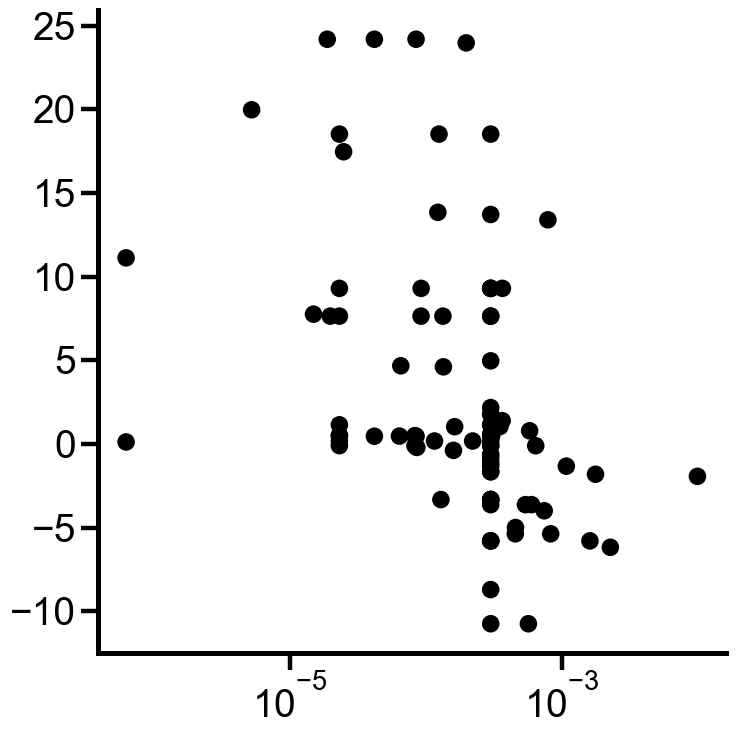

{'rho': -0.490719020353239,
 'p': 9.100900538647001e-07,
 'ci_low': -0.6329626712257196,
 'ci_high': -0.31498008196308525,
 'n': 90}

In [17]:
df = reaction_level[
    ~reaction_level["mean_delta_flux"].between(-0.1, 0.1)
]


fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    df["w"] / 1000 * 0.3,
    df["mean_delta_flux"],
    s=160,
    color="black",
    edgecolors="none"
)


ax.set_xscale("log")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

plt.tight_layout()
plt.show()

fig.savefig("Supp_Figure6_ececoli_weight.pdf", format="pdf", bbox_inches="tight", pad_inches=0.5)
spearman_ci(np.log(df["w"]), df["mean_delta_flux"])